# SaaS Subscription Renewal Prediction Using Decision Tree Classification
**Student:** Harshita Singh (Reg No. 2428010025, Section C) &nbsp;|&nbsp; **Supervisor:** Dr. Anshika Malsaria  
Department of Computer and Communication Engineering, Manipal University Jaipur

This notebook runs the project pipeline (`src/saas_renewal_prediction.py`) **cell by cell**, showing intermediate results.

## Step 0 — Imports & setup

In [1]:
import os, sys, json, logging
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
%matplotlib inline
sys.path.insert(0, 'src')
import saas_renewal_prediction as srp
logging.getLogger().setLevel(logging.WARNING); logging.getLogger('SaaSRenewal').setLevel(logging.WARNING)
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 30)

RAW_DIR, PROC_PATH = 'data/raw', 'data/processed/saas_processed.csv'
OUT_DIR, RES_DIR, FIG_DIR = 'outputs', 'results', 'figures'
for d in [RAW_DIR, os.path.dirname(PROC_PATH), OUT_DIR, RES_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)
print('Setup complete')

Setup complete


## Step 1 — Load & validate the raw multi-table dataset (RavenStack)

In [2]:
dfs = srp.load_and_validate_raw_data(RAW_DIR)
for name, d in dfs.items():
    print(f'{name:<20} rows={d.shape[0]:>6}  cols={d.shape[1]}')

feature_usage        rows= 25000  cols=8
subscriptions        rows=  5000  cols=14
support_tickets      rows=  2000  cols=9
churn_events         rows=   600  cols=9
accounts             rows=   500  cols=10


In [3]:
display(dfs['subscriptions'].head()) if 'subscriptions' in dfs else display(list(dfs.values())[0].head())

,subscription_id,account_id,start_date,end_date,plan_tier,seats,mrr_amount,arr_amount,is_trial,upgrade_flag,downgrade_flag,churn_flag,billing_frequency,auto_renew_flag
0,S-8cec59,A-3c1a3f,2023-12-23,2024-04-12,Enterprise,14,2786,33432,False,False,False,True,monthly,True
1,S-0f6f44,A-9b9fe9,2024-06-11,NaN,Pro,17,833,9996,False,False,False,False,monthly,True
2,S-51c0d1,A-659280,2024-11-25,NaN,Enterprise,62,0,0,True,True,False,False,annual,False
3,S-f81687,A-e7a1e2,2024-11-23,2024-12-13,Enterprise,5,995,11940,False,False,False,True,monthly,True
4,S-cff5a2,A-ba6516,2024-01-10,NaN,Enterprise,27,5373,64476,False,False,False,False,monthly,True


## Step 2 — Feature engineering within the observation window

In [4]:
df = srp.process_and_engineer_features(dfs, PROC_PATH)
print('Processed dataset shape:', df.shape)
display(df.head())

Processed dataset shape: (5000, 45)


,subscription_id,account_id,start_date,end_date,plan_tier,seats,mrr_amount,arr_amount,is_trial,upgrade_flag,downgrade_flag,churn_flag,billing_frequency,auto_renew_flag,start_date_dt,...,referral_source,signup_date_dt,tenure_days_at_start,total_tickets,mean_resolution_hours,mean_first_response_min,mean_satisfaction_score,total_escalations,urgent_high_tickets,in_cycle_tickets,escalation_rate,renewed,revenue_per_seat,is_high_value,start_date_str
0,S-8cec59,A-3c1a3f,2023-12-23,2024-04-12,Enterprise,14,2786,33432,False,False,False,True,monthly,True,2023-12-23,...,event,2023-08-26,119,4.0,33.25,56.50,3.500000,0.0,1.0,1.0,0.0,0,199.0,1,2023-12-23
1,S-0f6f44,A-9b9fe9,2024-06-11,NaN,Pro,17,833,9996,False,False,False,False,monthly,True,2024-06-11,...,other,2023-09-28,257,4.0,33.50,156.50,4.000000,0.0,2.0,2.0,0.0,1,49.0,0,2024-06-11
2,S-51c0d1,A-659280,2024-11-25,NaN,Enterprise,62,0,0,True,True,False,False,annual,False,2024-11-25,...,event,2023-11-17,374,4.0,8.00,123.75,4.333333,0.0,0.0,0.0,0.0,1,0.0,0,2024-11-25
3,S-f81687,A-e7a1e2,2024-11-23,2024-12-13,Enterprise,5,995,11940,False,False,False,True,monthly,True,2024-11-23,...,event,2024-06-23,153,1.0,45.00,37.00,4.000000,0.0,0.0,0.0,0.0,0,199.0,1,2024-11-23
4,S-cff5a2,A-ba6516,2024-01-10,NaN,Enterprise,27,5373,64476,False,False,False,False,monthly,True,2024-01-10,...,ads,2023-10-29,73,6.0,31.50,71.00,4.000000,0.0,1.0,4.0,0.0,1,199.0,1,2024-01-10


In [5]:
print('Target distribution (renewed):')
vc = df['renewed'].value_counts()
display(pd.DataFrame({'count': vc, 'percent': (vc / len(df) * 100).round(2)}))

Target distribution (renewed):


,count,percent
renewed,,
1,4514,90.28
0,486,9.72


## Step 3 — Customer-level train/test split (GroupShuffleSplit on `account_id`)

In [6]:
train_df, test_df = srp.split_data_customer_level(df, test_size=0.2, random_state=42)
overlap = set(train_df.account_id) & set(test_df.account_id)
print(f'Train: {len(train_df)} subscriptions / {train_df.account_id.nunique()} accounts')
print(f'Test : {len(test_df)} subscriptions / {test_df.account_id.nunique()} accounts')
print('Accounts shared between train and test:', len(overlap))

Train: 3982 subscriptions / 400 accounts
Test : 1018 subscriptions / 100 accounts
Accounts shared between train and test: 0


## Step 4 — Feature lists & preprocessing pipeline

In [7]:
num_features, cat_features = srp.get_feature_lists()
preprocessor = srp.build_preprocessing_pipeline(num_features, cat_features)
X_train, y_train, groups_train = train_df[num_features + cat_features], train_df['renewed'], train_df['account_id']
X_test, y_test = test_df[num_features + cat_features], test_df['renewed']
print('Numerical features :', num_features)
print('Categorical features:', cat_features)

Numerical features : ['seats', 'mrr_amount', 'arr_amount', 'revenue_per_seat', 'is_high_value', 'is_trial', 'upgrade_flag', 'downgrade_flag', 'auto_renew_flag', 'tenure_days_at_start', 'total_usage_events', 'total_usage_count', 'mean_usage_count', 'total_duration_secs', 'mean_duration_secs', 'total_errors', 'error_rate', 'distinct_features_used', 'beta_feature_usage_count', 'beta_feature_ratio', 'in_cycle_usage_count', 'total_tickets', 'mean_resolution_hours', 'mean_first_response_min', 'mean_satisfaction_score', 'total_escalations', 'urgent_high_tickets', 'in_cycle_tickets', 'escalation_rate']
Categorical features: ['plan_tier', 'billing_frequency', 'industry', 'referral_source']


## Step 5 — Tune the Decision Tree (GridSearchCV + StratifiedGroupKFold)

In [8]:
best_dt_pipe, best_dt_params, best_dt_cv_score = srp.tune_decision_tree_group_aware(
    X_train, y_train, groups_train, preprocessor, random_state=42)
print('Best hyperparameters:', best_dt_params)
print(f'Group-aware CV ROC-AUC: {best_dt_cv_score:.4f}')

Best hyperparameters: {'dt__class_weight': None, 'dt__criterion': 'entropy', 'dt__max_depth': 3, 'dt__min_samples_leaf': 5, 'dt__min_samples_split': 10}
Group-aware CV ROC-AUC: 0.6337


## Step 6 — Train comparative models (Logistic Regression, Random Forest, Majority Baseline)

In [9]:
comparative_models = srp.train_comparative_models_group_aware(
    X_train, y_train, groups_train, preprocessor, random_state=42)
all_models = {'Decision Tree': best_dt_pipe, **comparative_models}
print('Models trained:', list(all_models))

Models trained: ['Decision Tree', 'Logistic Regression', 'Random Forest', 'Majority Baseline']


## Step 7 — Evaluate on the untouched test set

In [10]:
metrics_summary, predictions_df = srp.evaluate_all_models(all_models, X_test, y_test)
predictions_df['subscription_id'] = test_df['subscription_id'].values
predictions_df['account_id'] = test_df['account_id'].values
predictions_df.to_csv(os.path.join(RES_DIR, 'test_predictions.csv'), index=False)
with open(os.path.join(RES_DIR, 'metrics.json'), 'w') as f:
    json.dump(metrics_summary, f, indent=4)

rows = {m: {k: v for k, v in d.items() if isinstance(v, (int, float))} for m, d in metrics_summary.items()}
display(pd.DataFrame(rows).T.round(4))

,accuracy,balanced_accuracy,roc_auc,f1_macro
Decision Tree,0.9077,0.5000,0.5928,0.4758
Logistic Regression,0.5295,0.5879,0.6102,0.4357
Random Forest,0.6444,0.5748,0.6204,0.4869
Majority Baseline,0.9077,0.5000,0.5000,0.4758


In [11]:
from sklearn.metrics import classification_report
print(classification_report(y_test, best_dt_pipe.predict(X_test), target_names=['Not Renewed (0)', 'Renewed (1)'], zero_division=0))

                 precision    recall  f1-score   support

Not Renewed (0)       0.00      0.00      0.00        94
    Renewed (1)       0.91      1.00      0.95       924

       accuracy                           0.91      1018
      macro avg       0.45      0.50      0.48      1018
   weighted avg       0.82      0.91      0.86      1018



## Step 8 — Decision rules & feature importance

In [12]:
import joblib
imp_df, all_feat_names, rules_txt = srp.extract_tree_rules_and_importance(best_dt_pipe, num_features, cat_features, OUT_DIR)
joblib.dump(best_dt_pipe, os.path.join(OUT_DIR, 'decision_tree_model.joblib'))
print(rules_txt)
display(imp_df.head(10))

|--- in_cycle_usage_count <= -0.71
|   |--- in_cycle_tickets <= 0.47
|   |   |--- total_duration_secs <= -1.19
|   |   |   |--- class: 1
|   |   |--- total_duration_secs >  -1.19
|   |   |   |--- class: 1
|   |--- in_cycle_tickets >  0.47
|   |   |--- total_usage_events <= -0.19
|   |   |   |--- class: 1
|   |   |--- total_usage_events >  -0.19
|   |   |   |--- class: 1
|--- in_cycle_usage_count >  -0.71
|   |--- in_cycle_usage_count <= 1.89
|   |   |--- mean_first_response_min <= 1.82
|   |   |   |--- class: 1
|   |   |--- mean_first_response_min >  1.82
|   |   |   |--- class: 1
|   |--- in_cycle_usage_count >  1.89
|   |   |--- mean_first_response_min <= 1.37
|   |   |   |--- class: 1
|   |   |--- mean_first_response_min >  1.37
|   |   |   |--- class: 1



,feature,importance
0,in_cycle_usage_count,0.600856
1,mean_first_response_min,0.149272
2,in_cycle_tickets,0.118565
3,total_duration_secs,0.084244
4,total_usage_events,0.047062
5,industry_HealthTech,0.000000
6,industry_FinTech,0.000000
7,industry_EdTech,0.000000
8,industry_DevTools,0.000000
9,billing_frequency_monthly,0.000000


## Step 9 — Generate & display publication figures

In [13]:
srp.generate_publication_figures(df, all_models, X_test, y_test, imp_df, all_feat_names, FIG_DIR)
print(sorted(os.listdir(FIG_DIR)))

['fig1_class_distribution.png', 'fig2_eda_features.png', 'fig3_confusion_matrices.png', 'fig4_roc_curves.png', 'fig5_decision_tree_visualization.png', 'fig6_feature_importance.png', 'manipal_logo.png']


### Class distribution

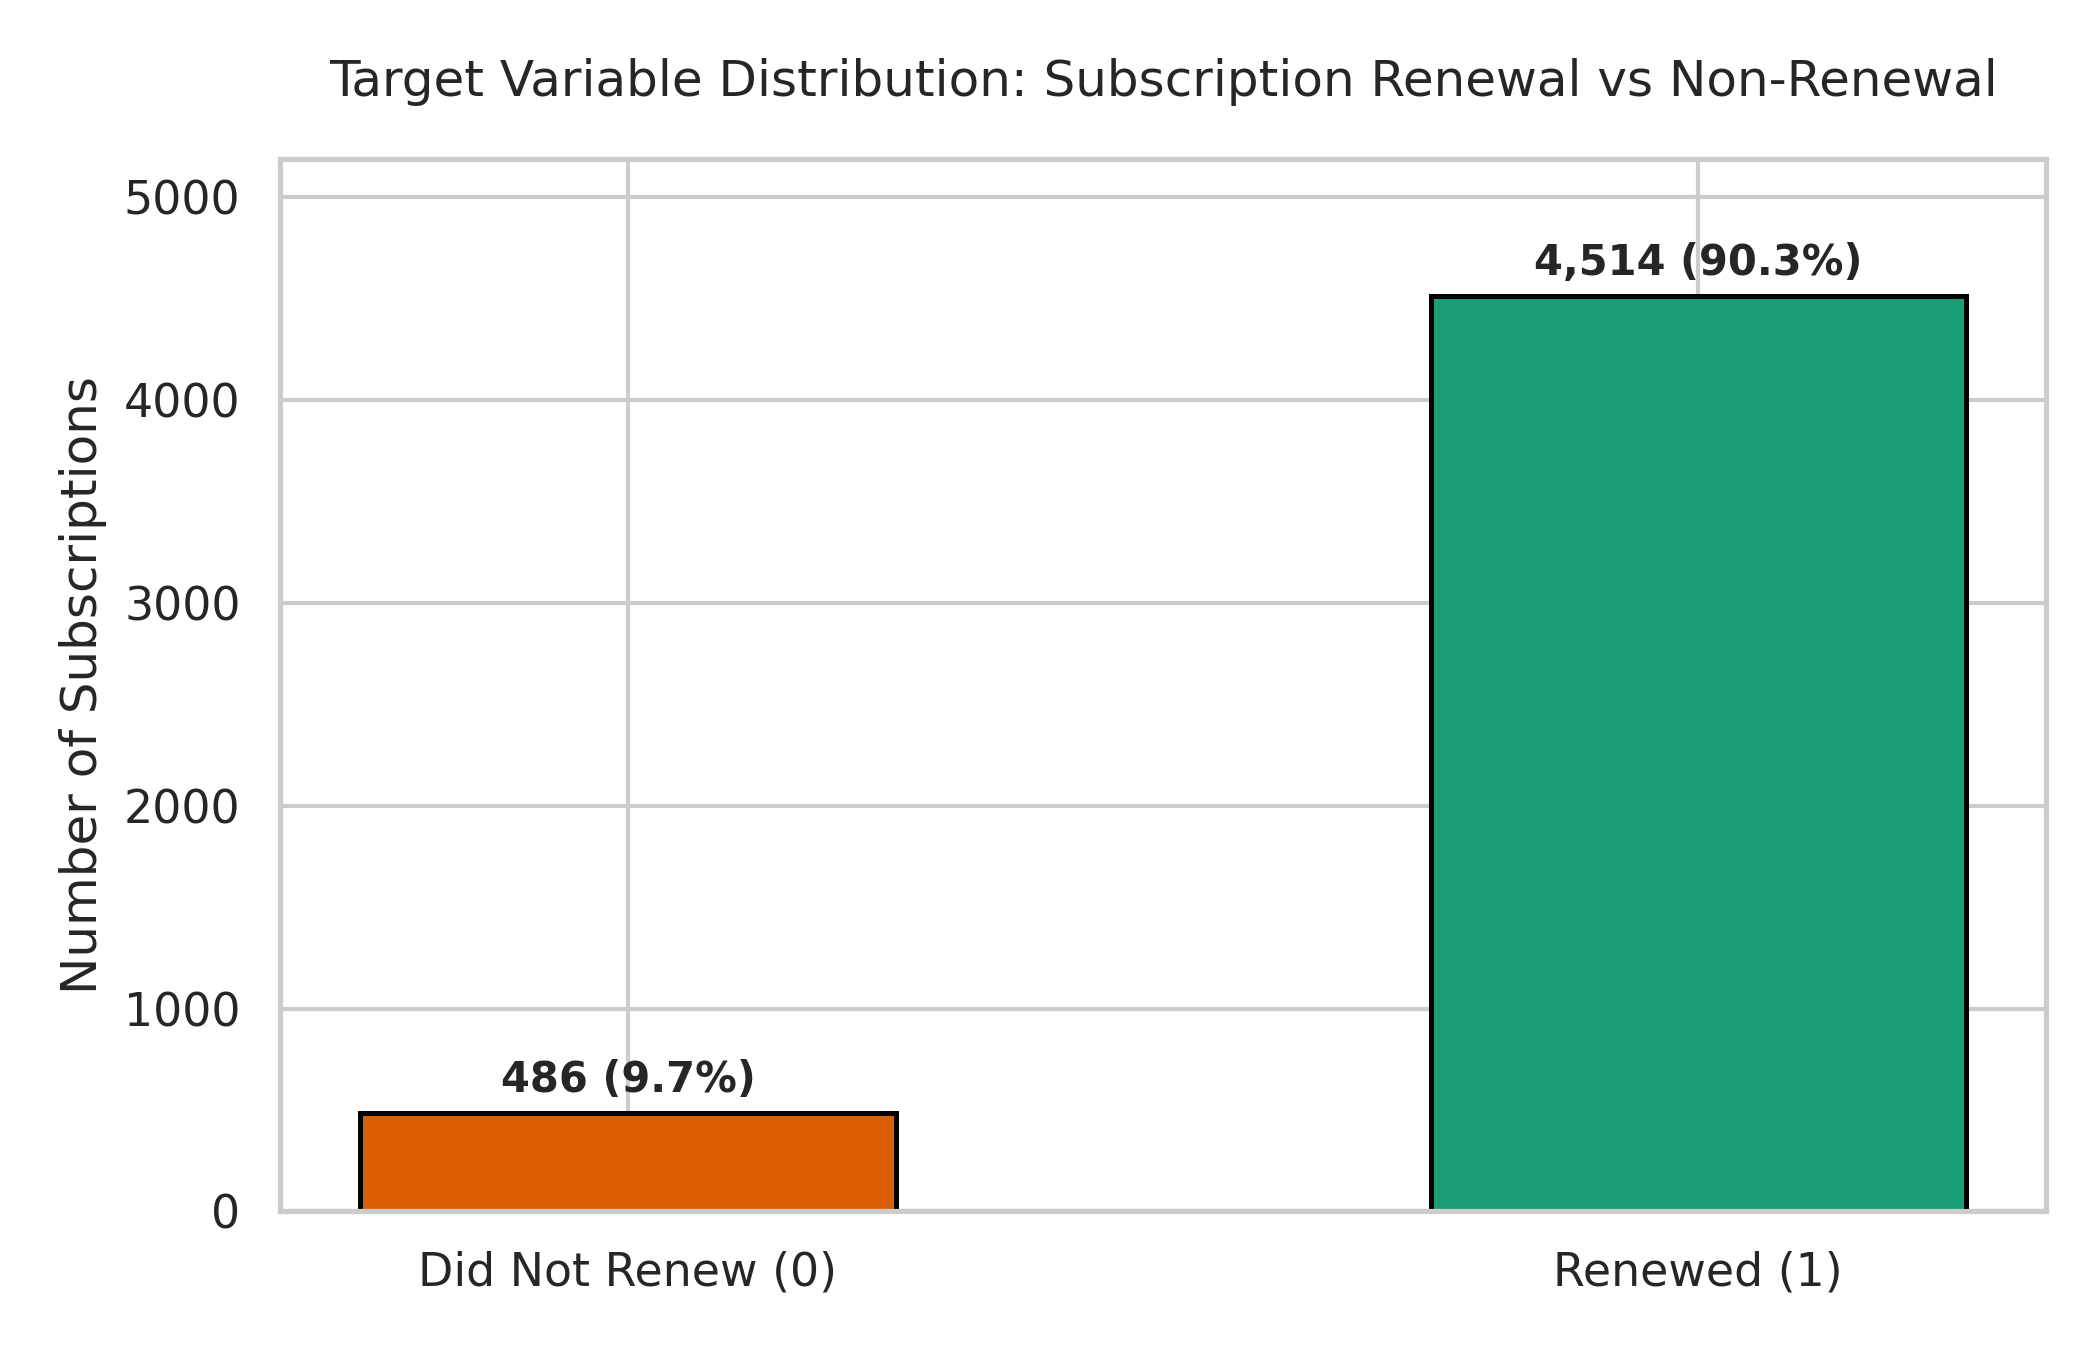

In [14]:
display(Image(filename=os.path.join(FIG_DIR, 'fig1_class_distribution.png'), width=850))

### EDA features

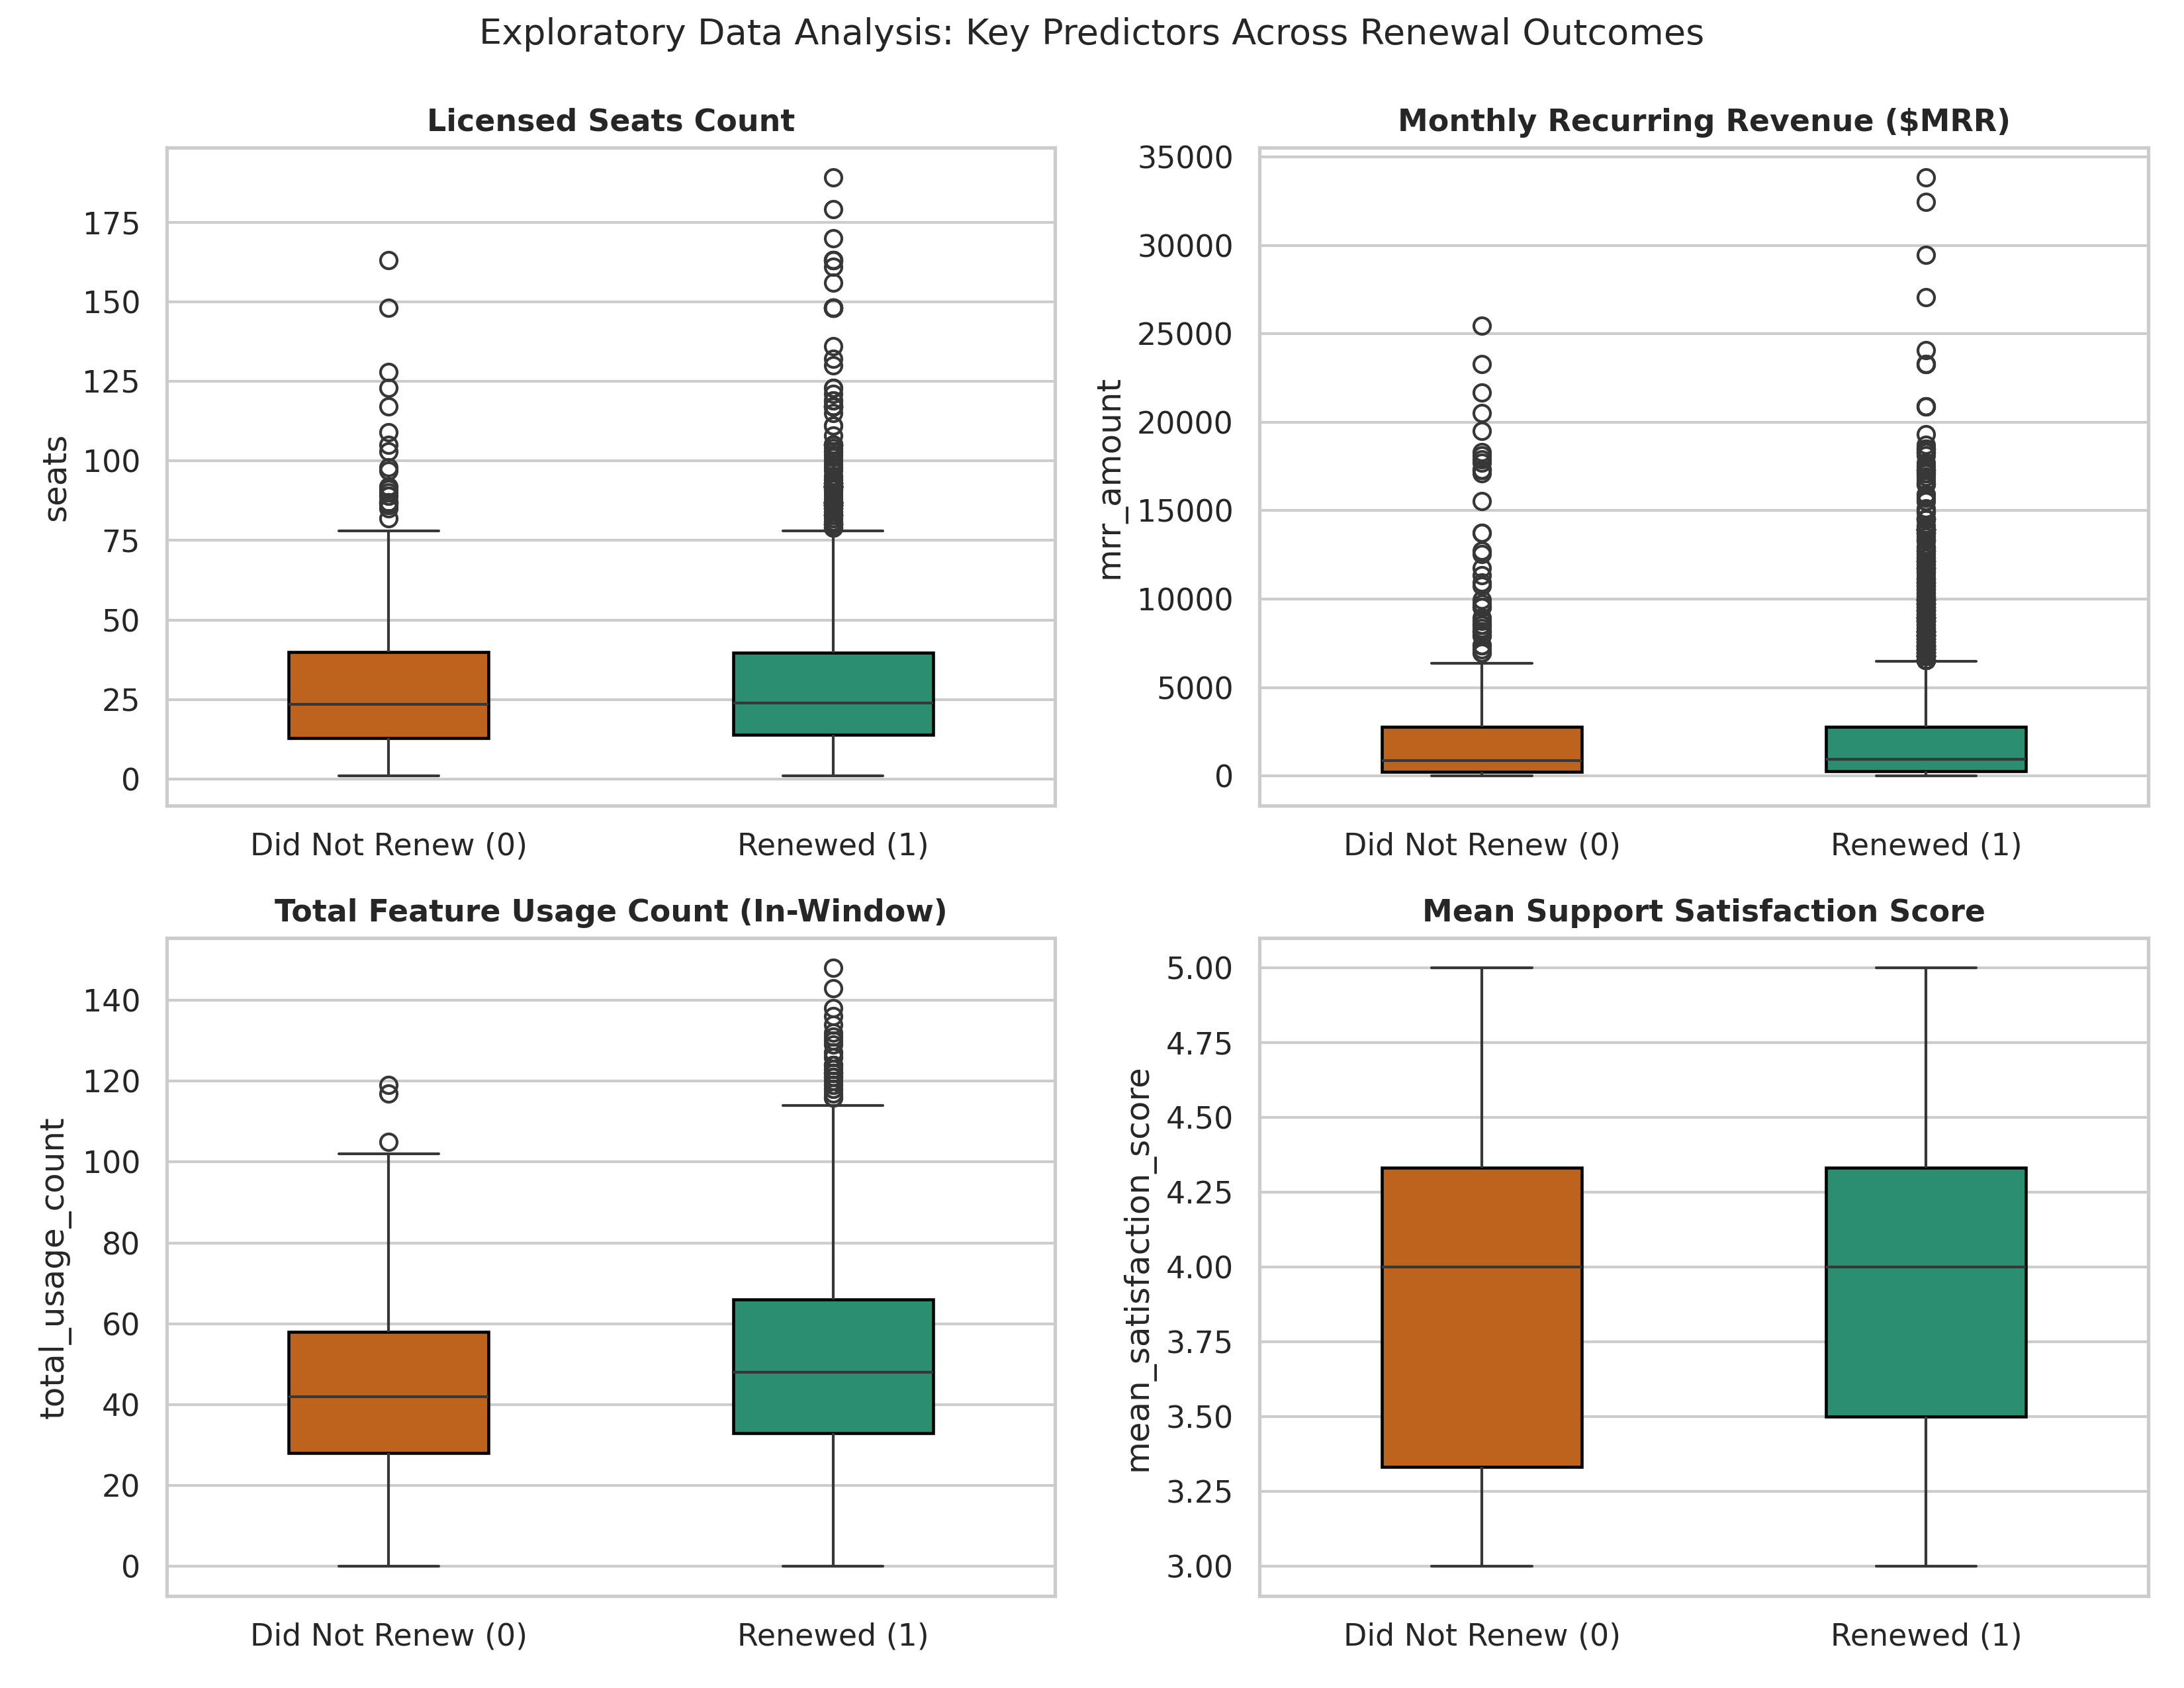

In [15]:
display(Image(filename=os.path.join(FIG_DIR, 'fig2_eda_features.png'), width=850))

### Confusion matrices

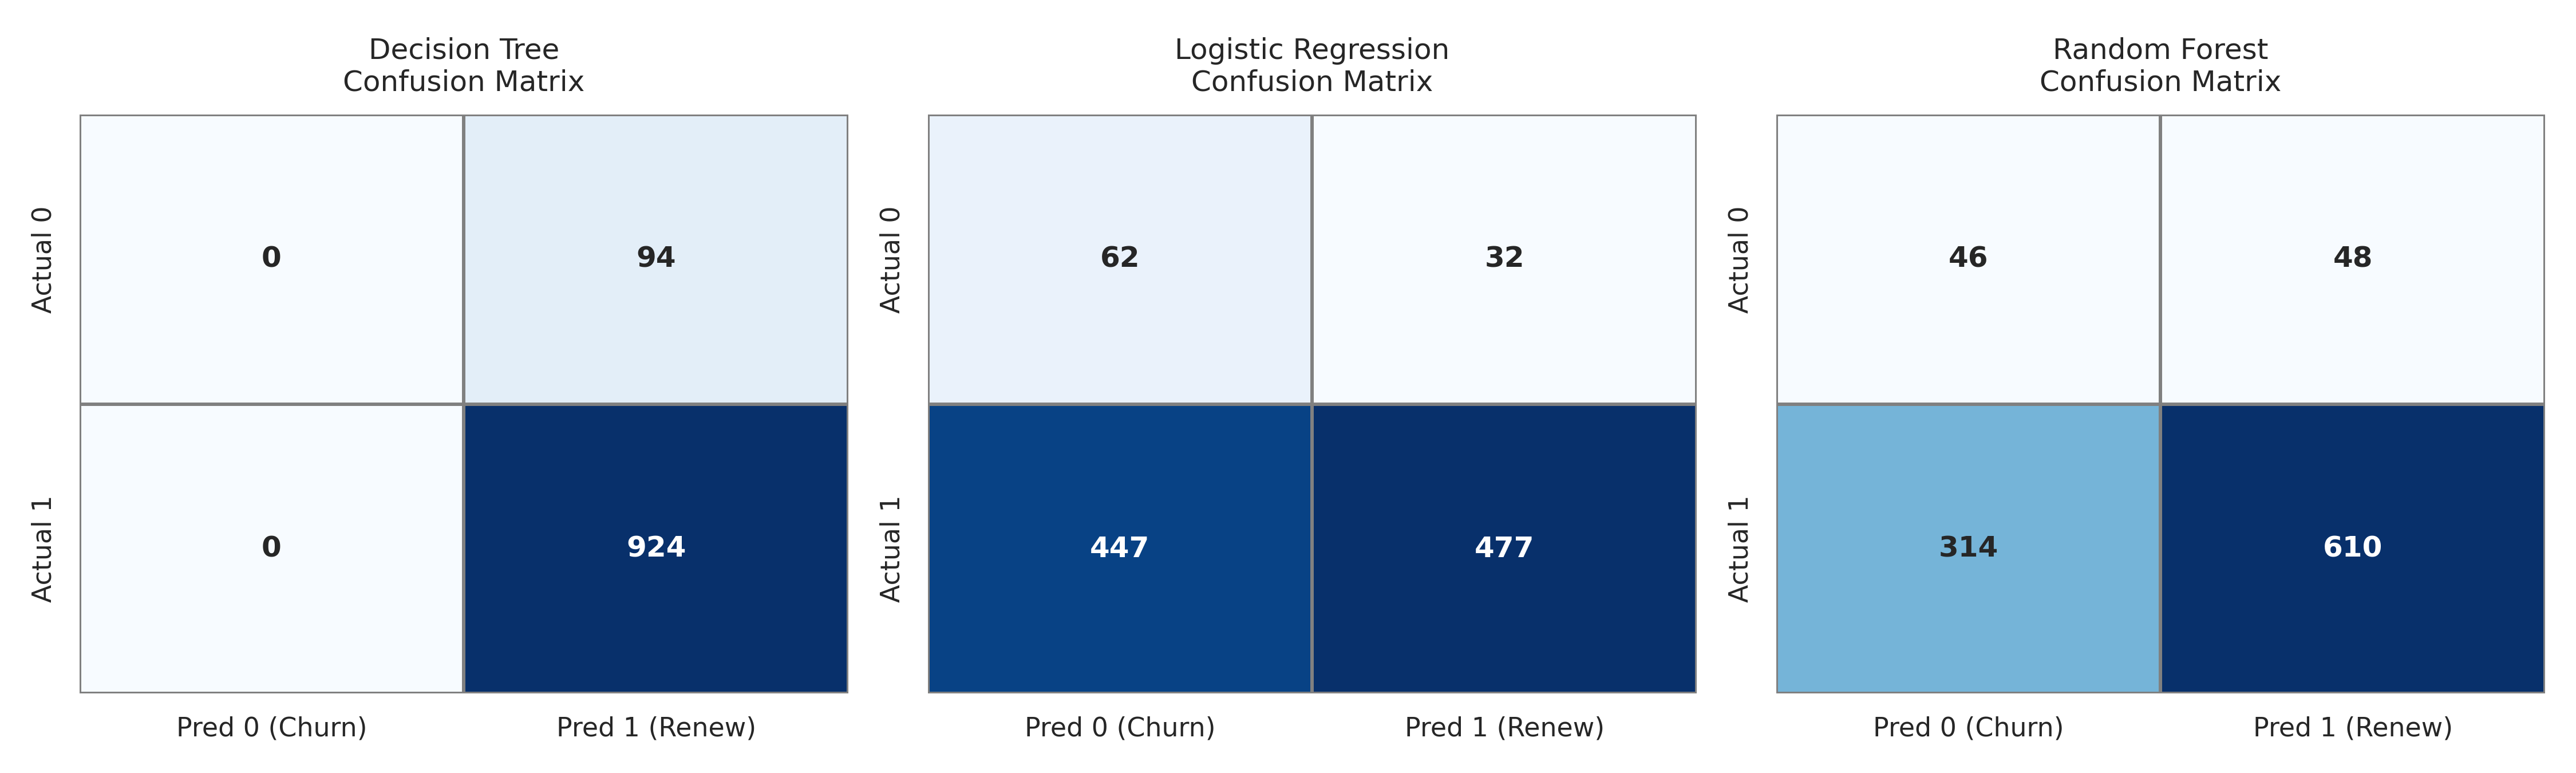

In [16]:
display(Image(filename=os.path.join(FIG_DIR, 'fig3_confusion_matrices.png'), width=850))

### ROC curves

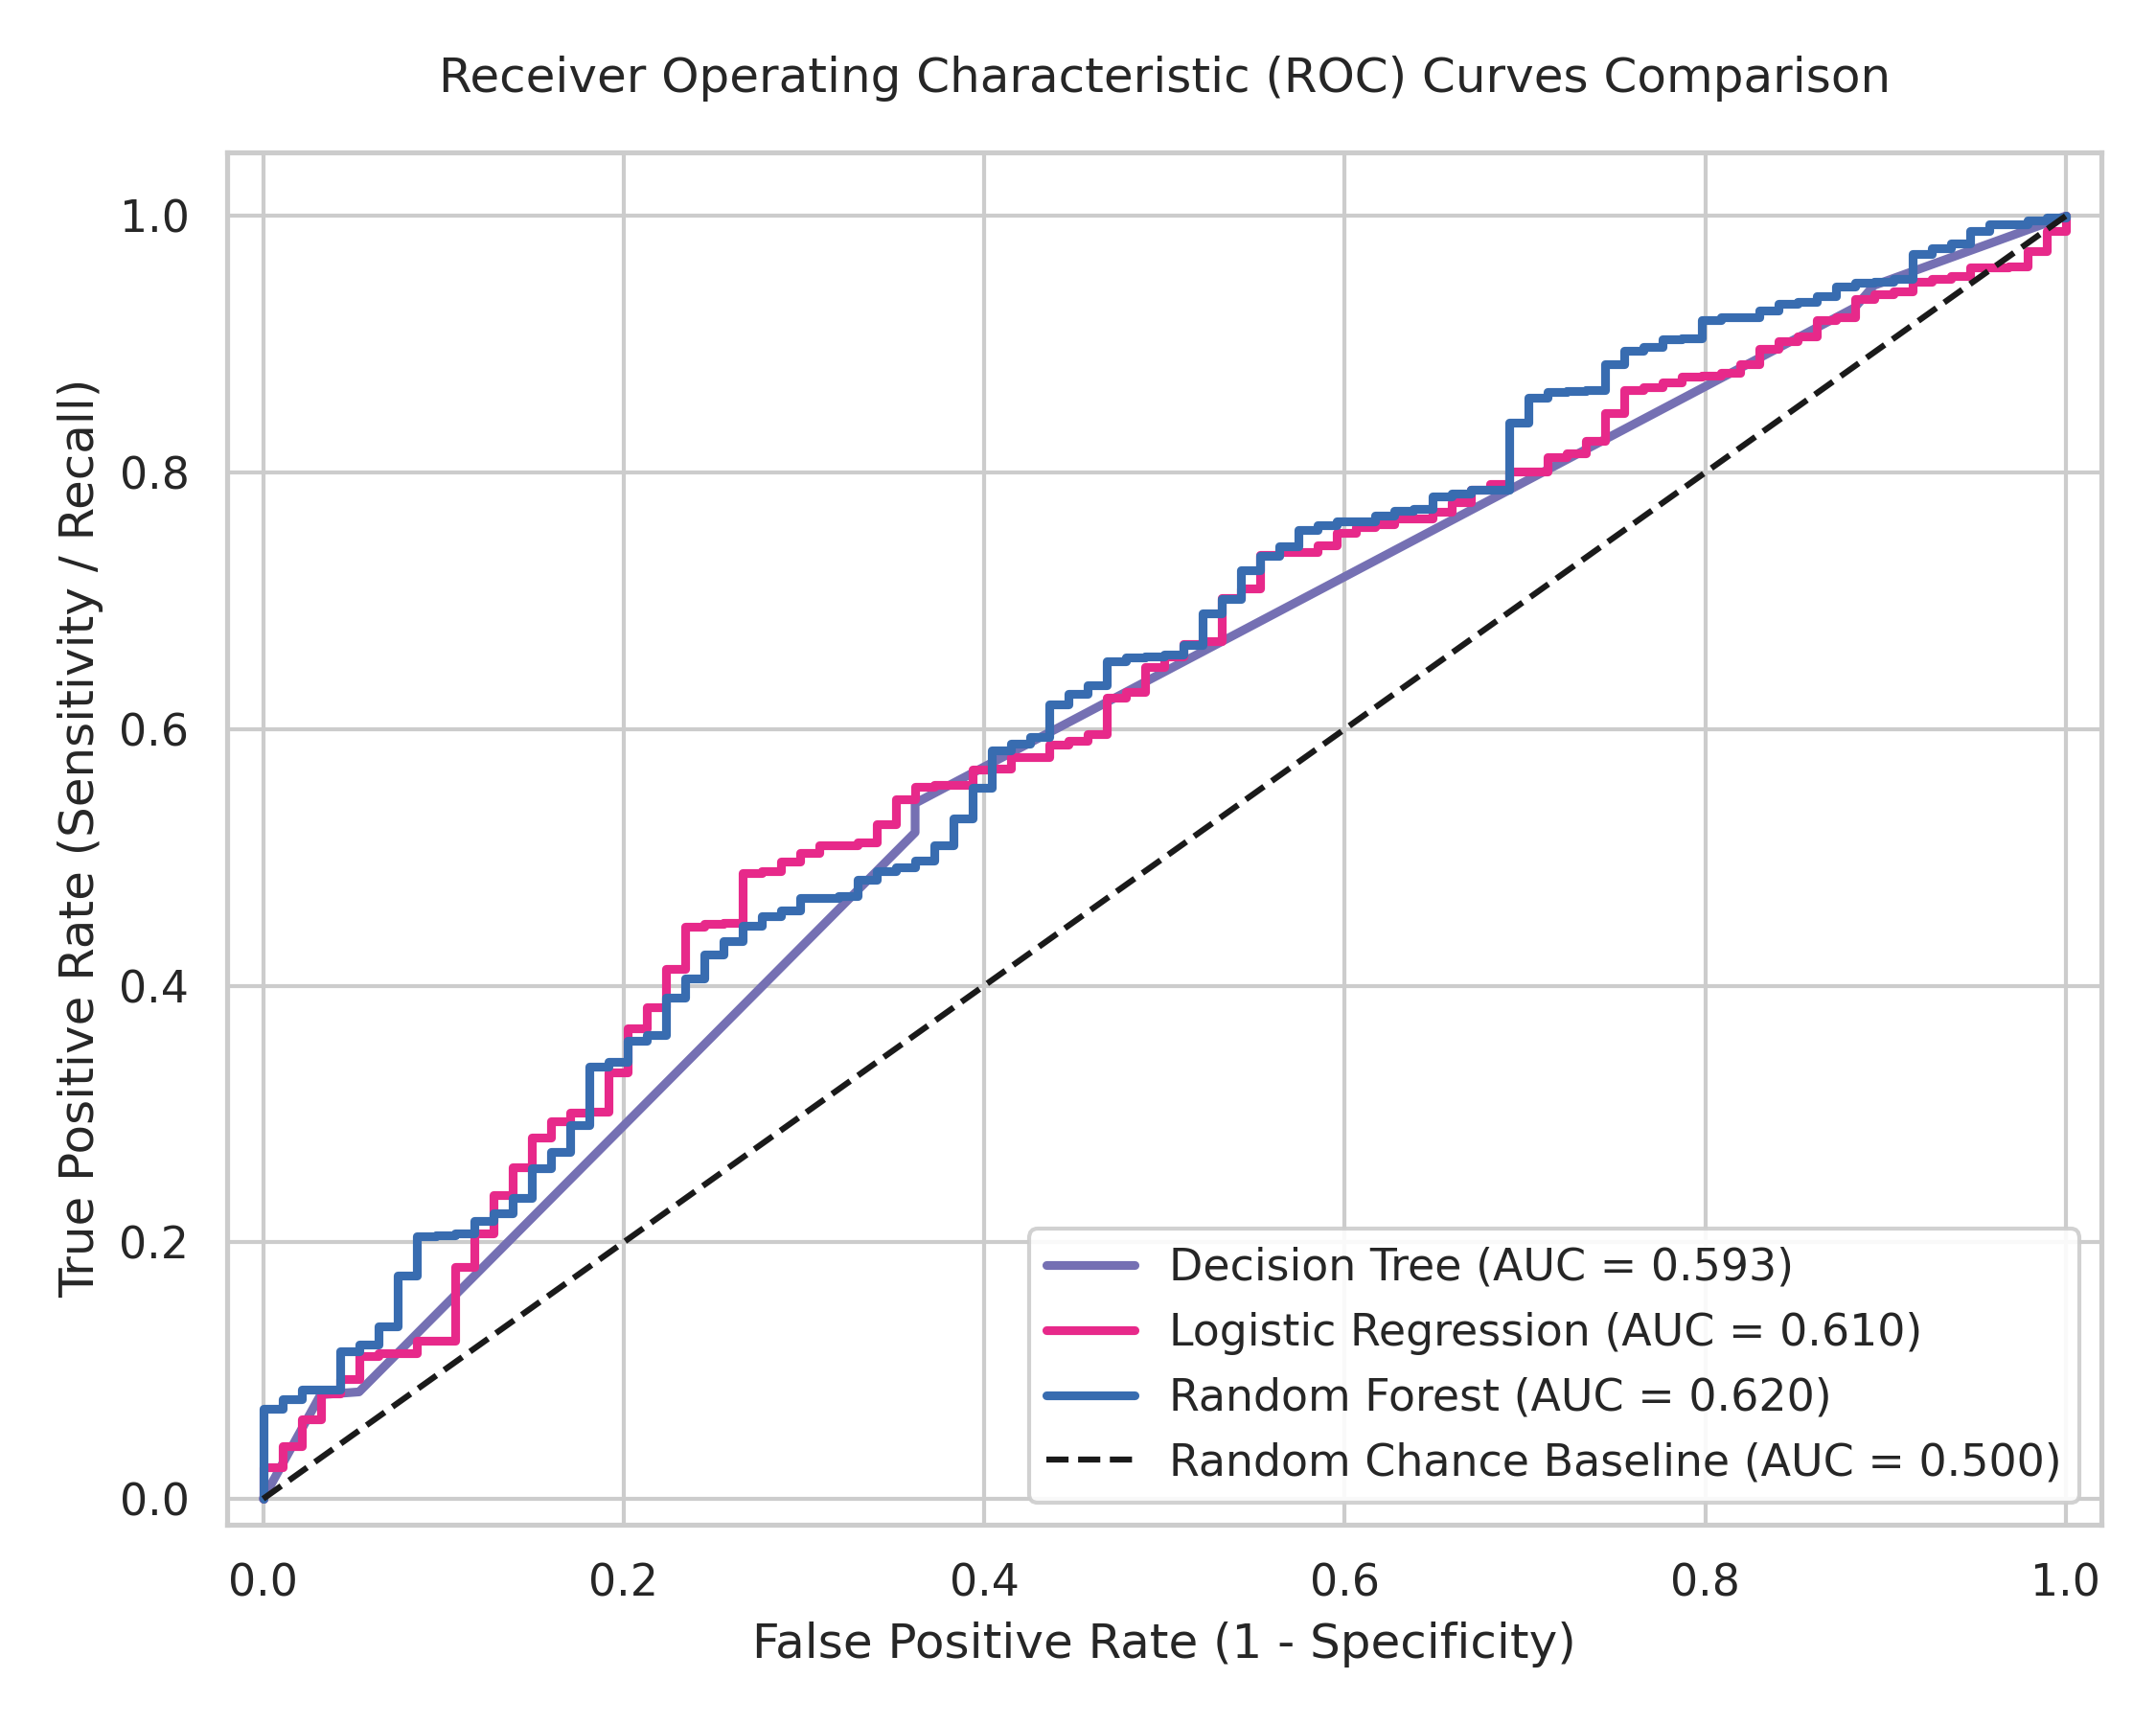

In [17]:
display(Image(filename=os.path.join(FIG_DIR, 'fig4_roc_curves.png'), width=850))

### Decision tree

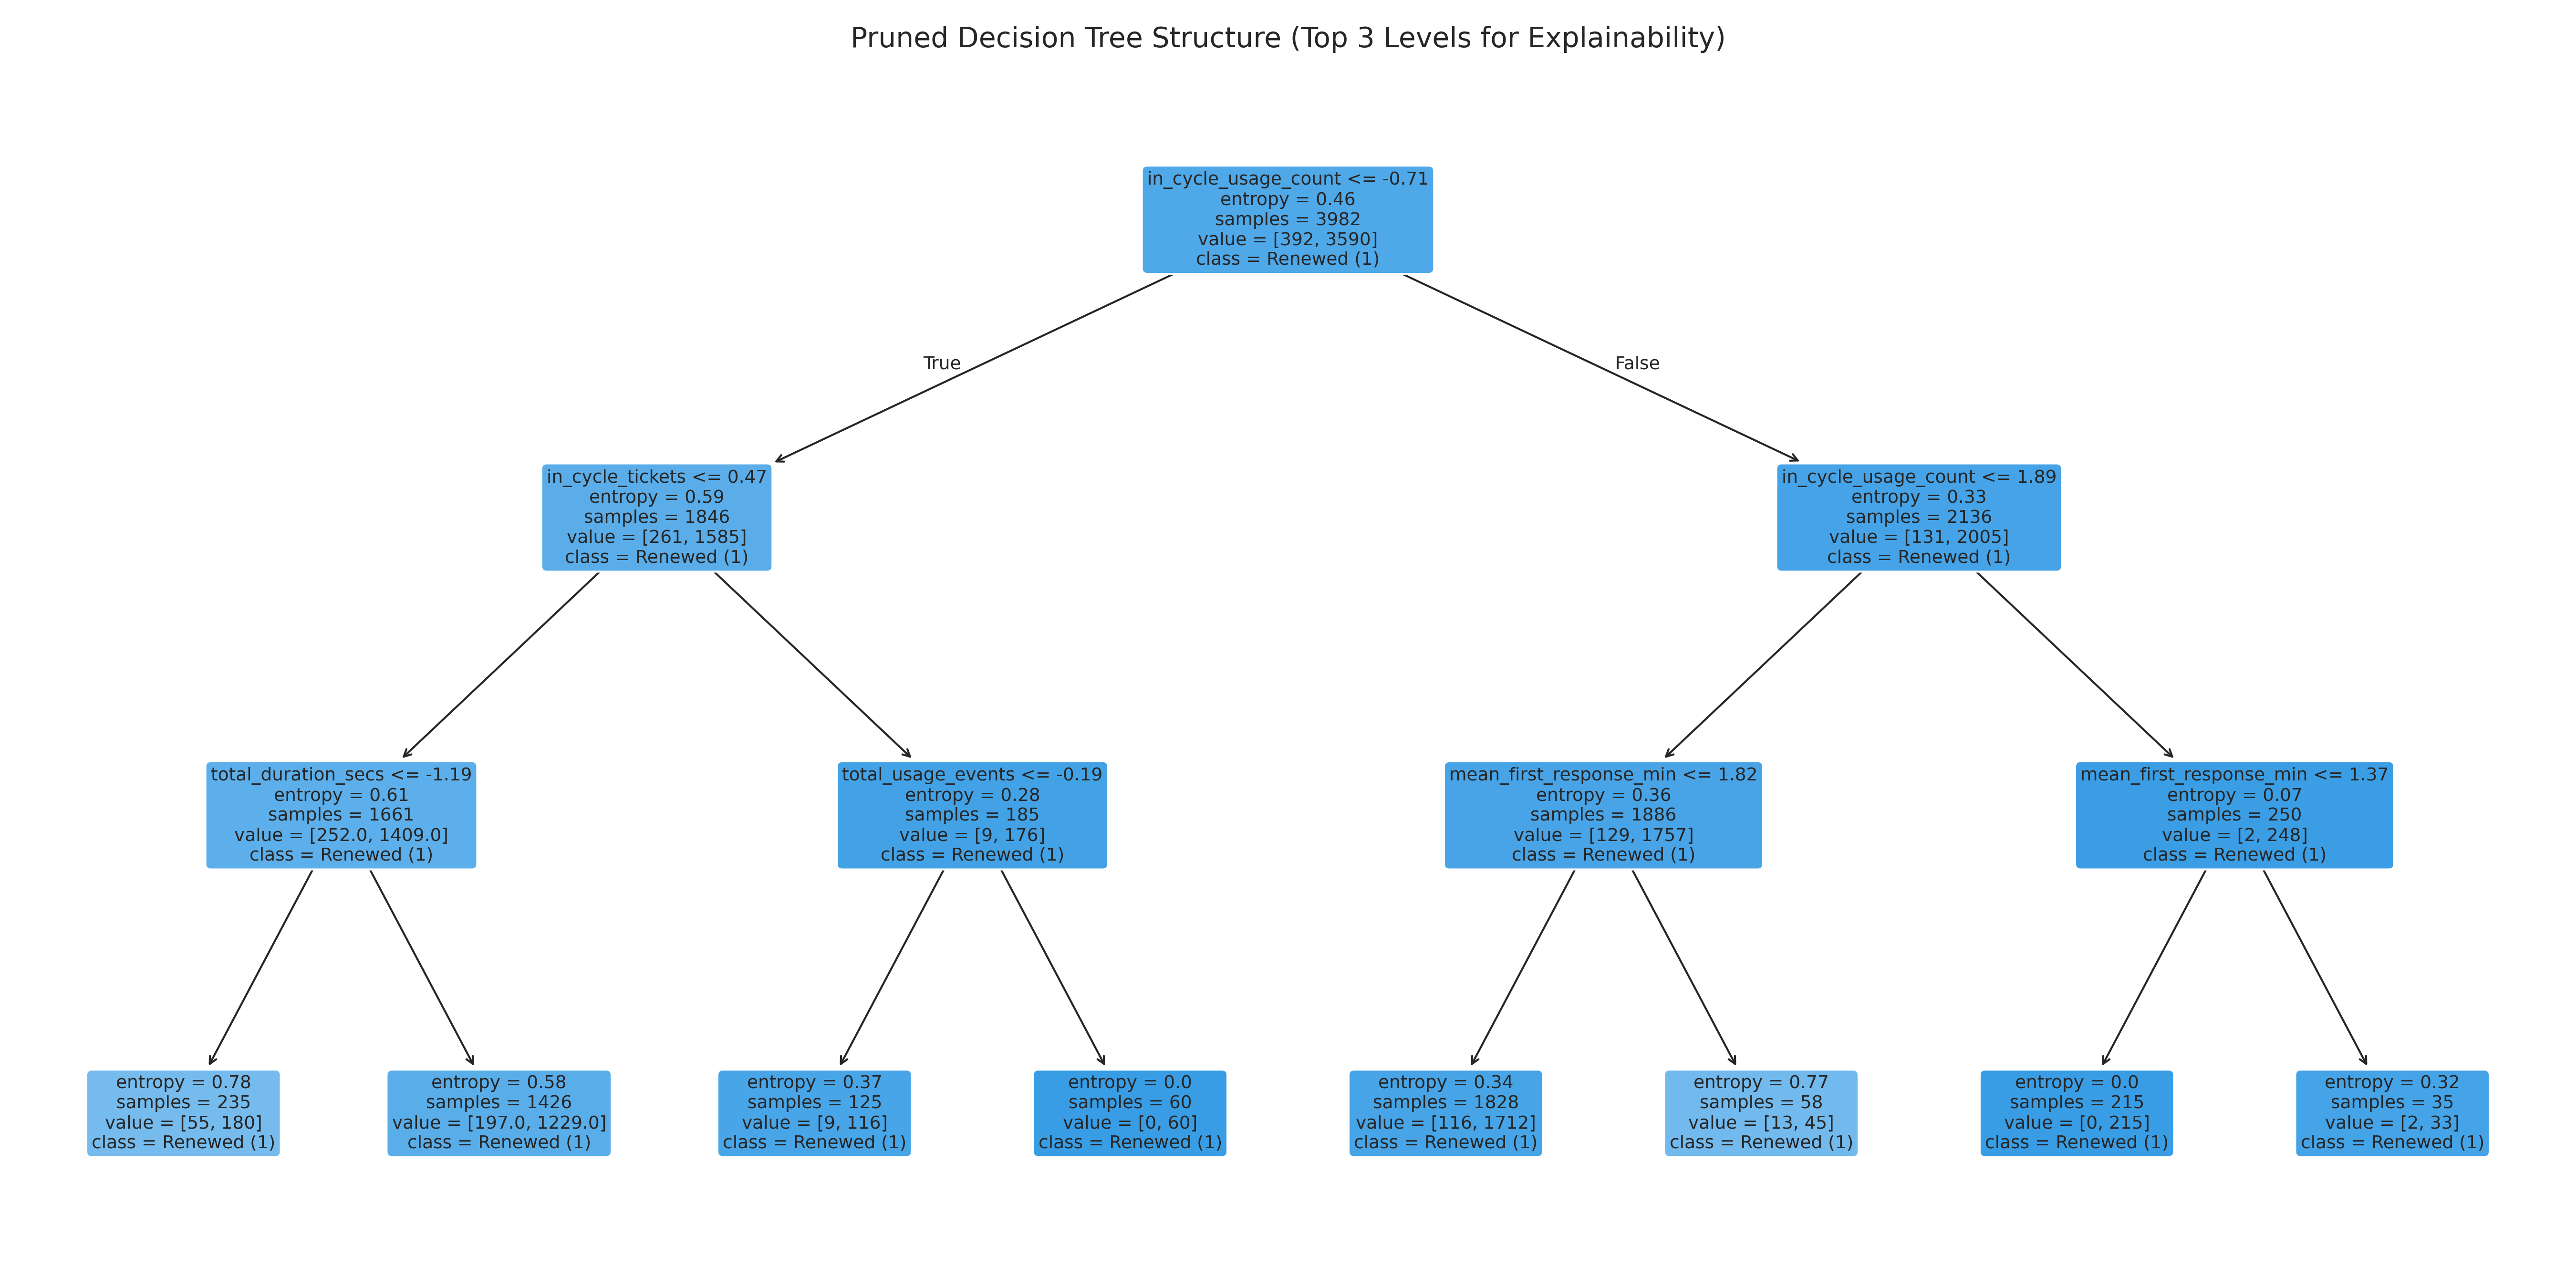

In [18]:
display(Image(filename=os.path.join(FIG_DIR, 'fig5_decision_tree_visualization.png'), width=850))

### Feature importance

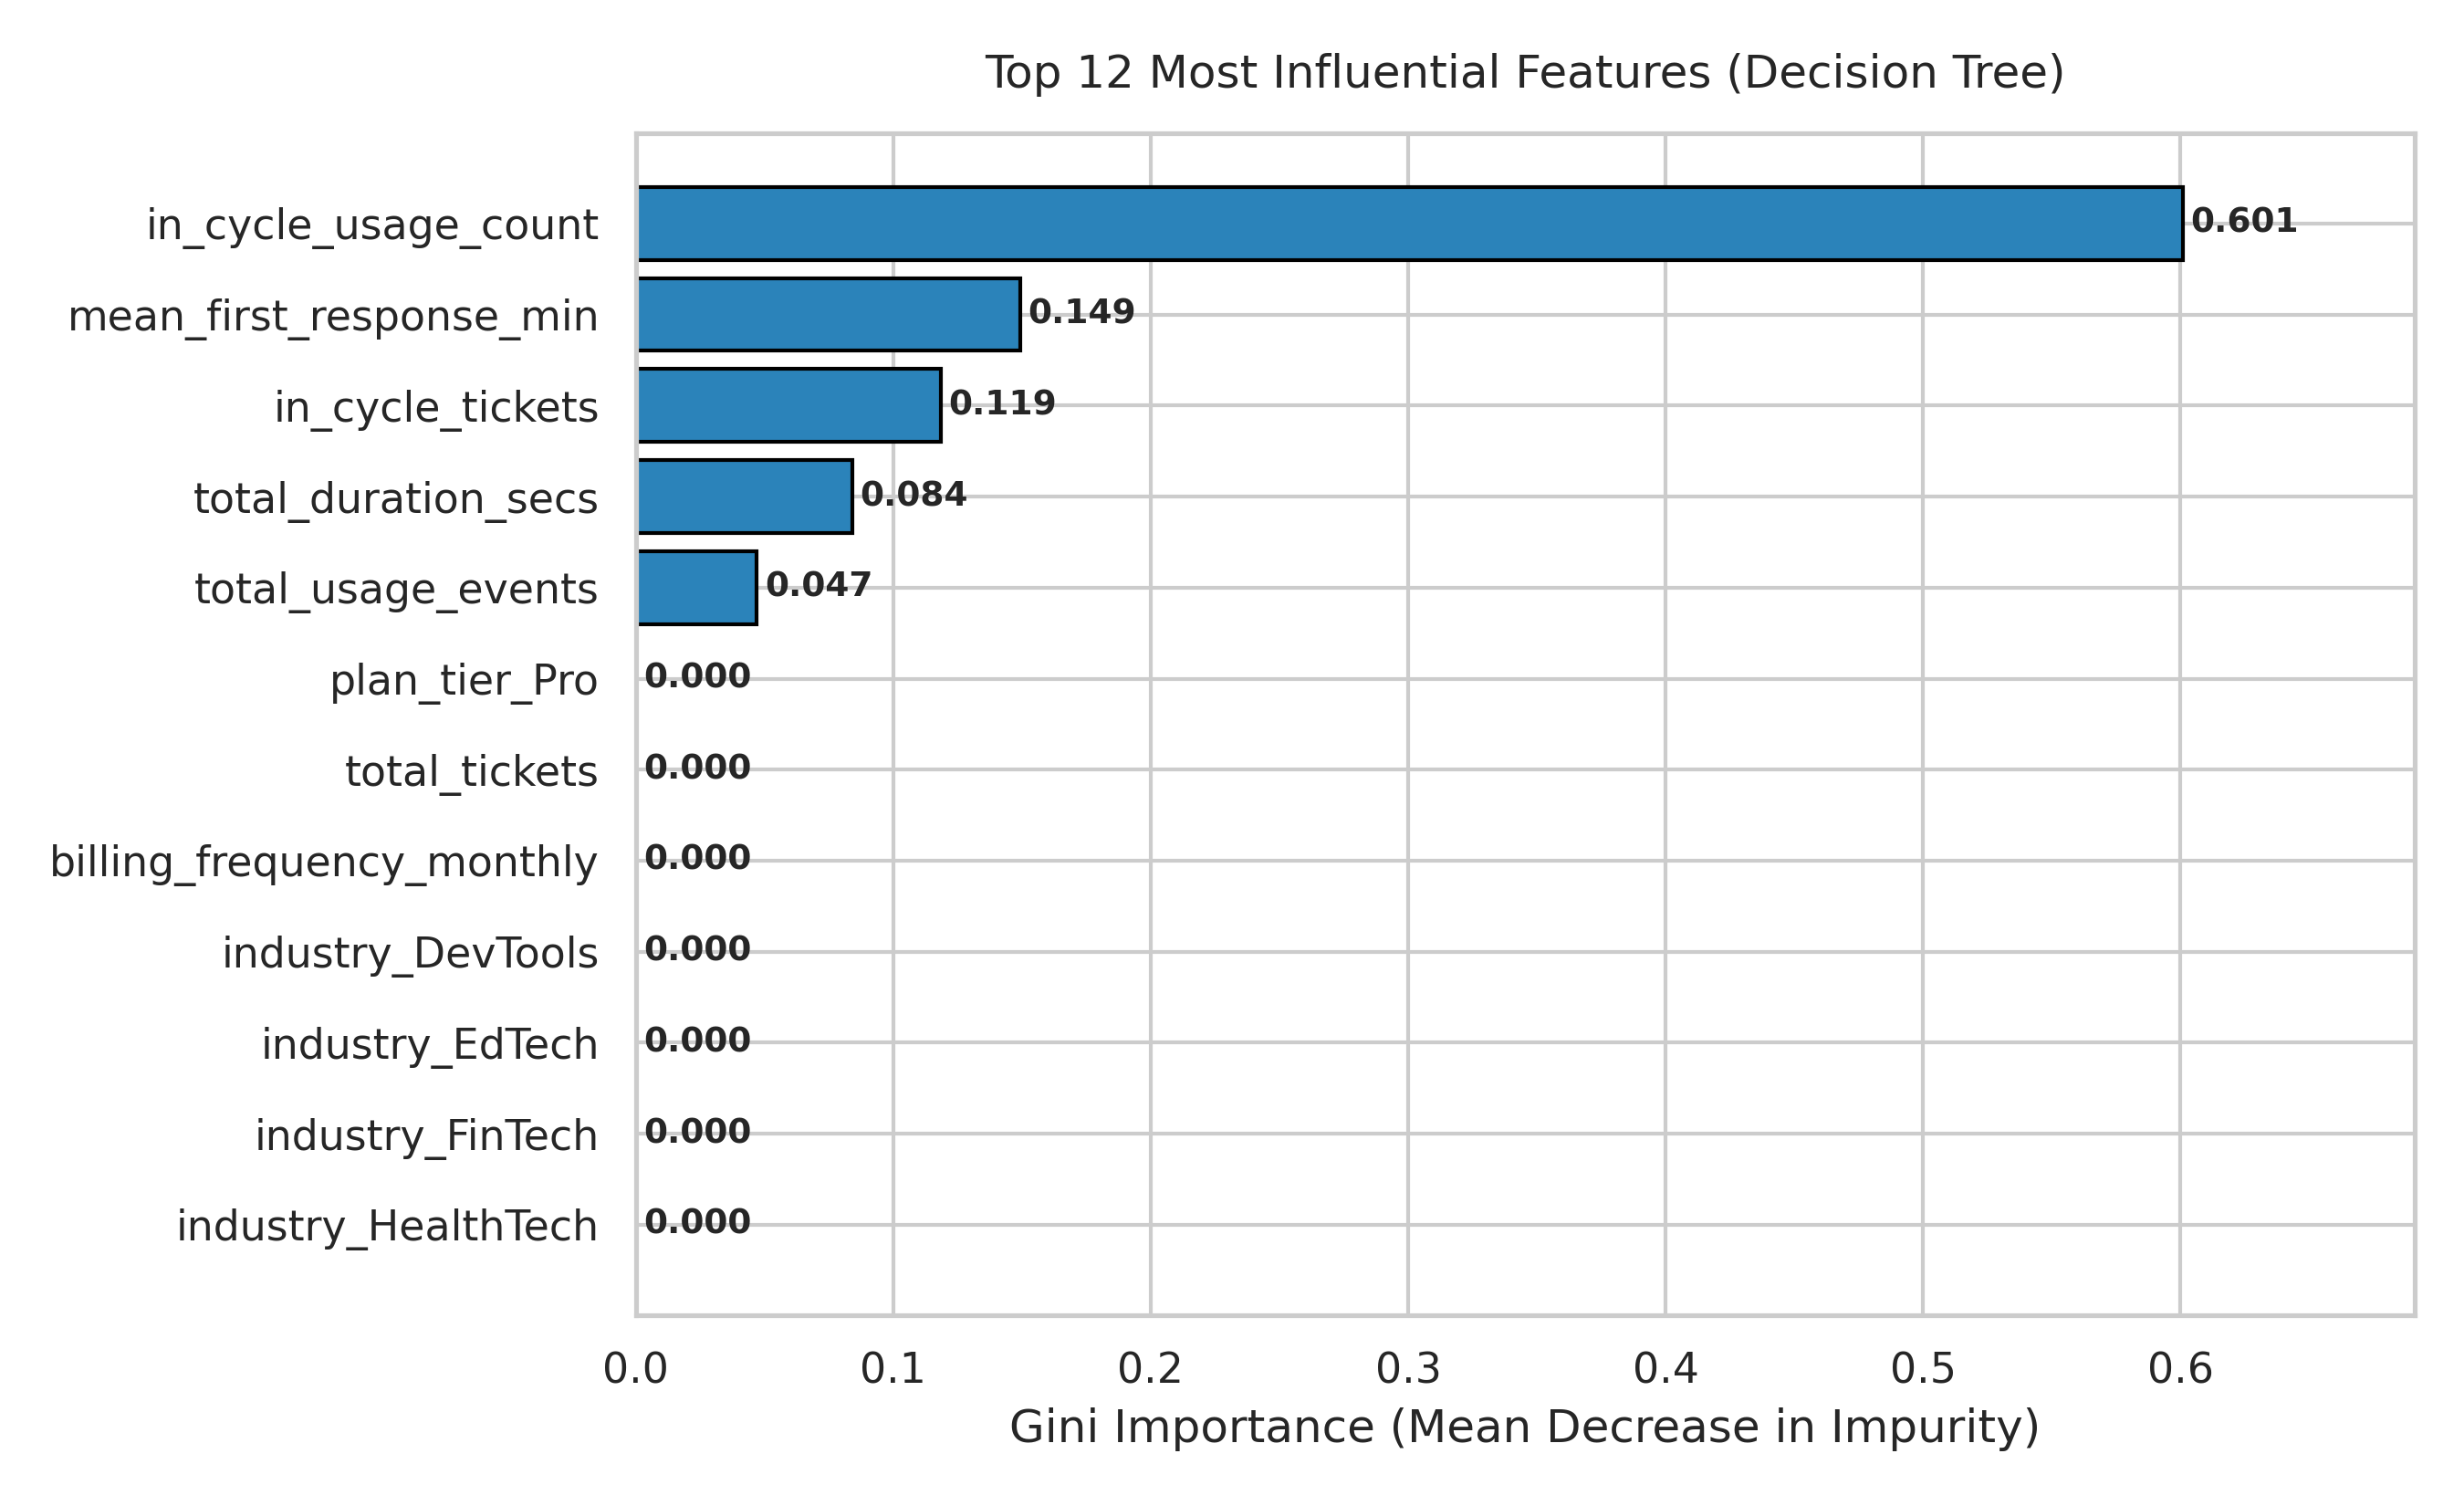

In [19]:
display(Image(filename=os.path.join(FIG_DIR, 'fig6_feature_importance.png'), width=850))

## Summary

In [20]:
dt = metrics_summary['Decision Tree']
print(f"Decision Tree -> Accuracy: {dt['accuracy']:.4f} | ROC-AUC: {dt['roc_auc']:.4f} | Macro-F1: {dt['f1_macro']:.4f}")
print(f"CV ROC-AUC (group-aware): {best_dt_cv_score:.4f}")

Decision Tree -> Accuracy: 0.9077 | ROC-AUC: 0.5928 | Macro-F1: 0.4758
CV ROC-AUC (group-aware): 0.6337
